<a href="https://colab.research.google.com/github/pritiii05/DEEP-LEARNING/blob/main/Experiment3_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
data = load_breast_cancer()
X, y = data.data, data.target
print("Samples:", X.shape[0], "| Features:", X.shape[1])
print("Malignant:", int((y == 0).sum()), "| Benign:", int((y == 1).sum()))

Samples: 569 | Features: 30
Malignant: 212 | Benign: 357


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

In [ ]:
def sigmoid(z):
  return 1.0 / (1.0 + np.exp(-z))

class SigmoidNeuron:
    def __init__(self, n_features, lr=0.1, epochs=300):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr, self.epochs = lr, epochs
        self.losses = []

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def fit(self, X, y):
        n = len(y)
        for _ in range(self.epochs):
            p = self.predict_proba(X)
            loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
            self.losses.append(loss)
            error = p - y
            self.w -= self.lr * (X.T @ error) / n
            self.b -= self.lr * error.mean()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = SigmoidNeuron(X_train.shape[1])
model.fit(X_train, y_train)
print("\nLoss at epoch 1 :", round(model.losses[0], 4))
print("Loss at epoch 100:", round(model.losses[99], 4))
print("Loss at epoch 300:", round(model.losses[-1], 4))


Loss at epoch 1 : 0.6931
Loss at epoch 100: 0.0986
Loss at epoch 300: 0.0723


In [ ]:
pred = model.predict(X_test)
print("\nTrain accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))
print("Test accuracy :", round(accuracy_score(y_test, pred), 4))
print("Confusion matrix (rows = actual, columns = predicted):")
cm = confusion_matrix(y_test, pred)
print(cm)


Train accuracy: 0.9868
Test accuracy : 0.9737
Confusion matrix (rows = actual, columns = predicted):
[[41  1]
 [ 2 70]]


In [ ]:
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print("Malignant as positive: TP =", tp, "FN =", fn, "FP =", fp, "TN =", tn)
print("Precision:", round(tp / (tp + fp), 4), "| Recall:", round(tp / (tp + fn), 4))

Malignant as positive: TP = 41 FN = 1 FP = 2 TN = 70
Precision: 0.9535 | Recall: 0.9762


In [ ]:
ref = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print("\nscikit-learn test accuracy:", round(accuracy_score(y_test, ref.predict(X_test)), 4))
print("Predictions that differ from scikit-learn:", int((pred != ref.predict(X_test)).sum()), "of", len(y_test))


scikit-learn test accuracy: 0.9825
Predictions that differ from scikit-learn: 1 of 114


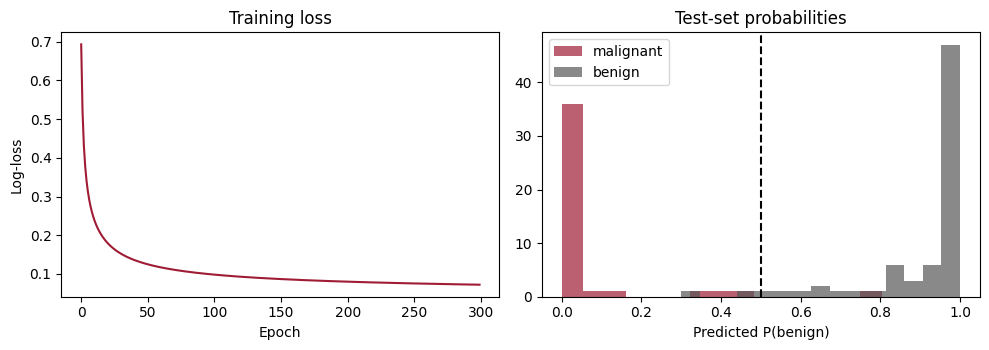

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(model.losses, color="#9F1C34")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Log-loss"); ax[0].set_title("Training loss")
ax[1].hist(model.predict_proba(X_test[y_test == 0]), bins=15, alpha=0.7,
           label="malignant", color="#9F1C34")
ax[1].hist(model.predict_proba(X_test[y_test == 1]), bins=15, alpha=0.7, label="benign",
           color="#575759")
ax[1].axvline(0.5, color="k", linestyle="--")
ax[1].set_xlabel("Predicted P(benign)"); ax[1].set_title("Test-set probabilities")
ax[1].legend()
plt.tight_layout(); plt.show()